# Regresión Lineal Múltiple: costos de seguro médico

**Programación Python Avanzada — TUTP 2026 — Proyecto 2, segunda parte**

Integrantes: *completar*

**Dataset:** [Medical Cost Personal Datasets (Kaggle)](https://www.kaggle.com/datasets/mirichoi0218/insurance), archivo `insurance.csv`. Tiene 1338 personas aseguradas en EE.UU. con estas columnas:

| Columna | Tipo | Descripción |
|---|---|---|
| `age` | numérica | edad del titular (años) |
| `sex` | categórica | sexo (`female` / `male`) |
| `bmi` | numérica | índice de masa corporal (kg/m²) |
| `children` | numérica | cantidad de hijos cubiertos por el seguro |
| `smoker` | categórica | si fuma (`yes` / `no`) |
| `region` | categórica | región de residencia en EE.UU. |
| **`charges`** | numérica | **costo médico anual facturado por el seguro (USD) → variable a predecir (Y)** |

**Objetivo:** predecir `charges` a partir de las *features* numéricas `age`, `bmi` y `children` (X) con un modelo de Regresión Lineal Múltiple, evaluarlo y analizar su capacidad de predicción. Al final probamos si agregar otras variables mejora el modelo.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
os.makedirs("graficos", exist_ok=True)

## 1. Carga de datos y visualización de variables

In [2]:
# Si el CSV está junto al notebook (Jupyter o repo clonado) se usa ese archivo;
# en Colab, si no está, se descarga desde el repositorio de GitHub.
ARCHIVO = "insurance.csv"
URL_CSV = ("https://raw.githubusercontent.com/SofiMartin/proyecto2-python-avanzado/"
           "main/parte2_regresion/insurance.csv")
URL_RESPALDO = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

if os.path.exists(ARCHIVO):
    df = pd.read_csv(ARCHIVO)
else:
    try:
        df = pd.read_csv(URL_CSV)
    except Exception:
        df = pd.read_csv(URL_RESPALDO)

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores faltantes por columna:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Filas duplicadas: 1


No hay valores faltantes. Hay **una fila duplicada**: dos personas con exactamente los mismos datos. Es perfectamente posible en la realidad (dos personas de 19 años, mismo IMC, etc.), así que la dejamos.

In [5]:
df.describe().round(2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


### Distribución de la variable a predecir y de las features

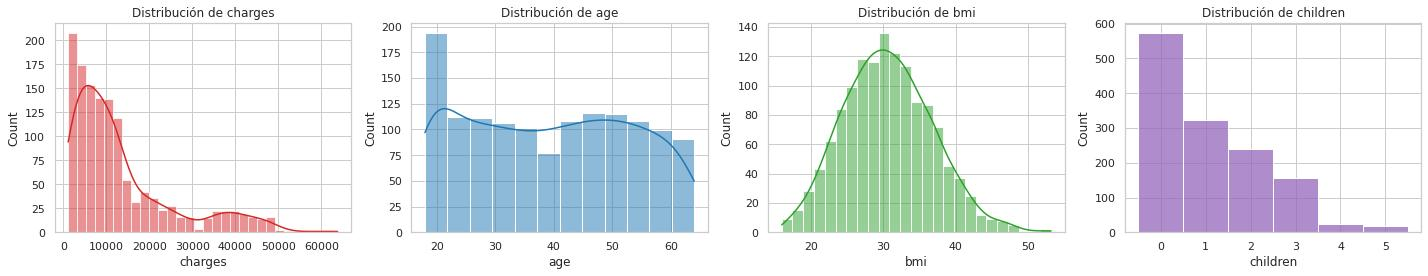

In [6]:
fig, ejes = plt.subplots(1, 4, figsize=(20, 4))
for eje, col, color in zip(ejes, ["charges", "age", "bmi", "children"],
                           ["tab:red", "tab:blue", "tab:green", "tab:purple"]):
    sns.histplot(df[col], kde=col != "children", ax=eje, color=color,
                 discrete=col == "children")
    eje.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.savefig("graficos/1_distribuciones.png", dpi=100, bbox_inches="tight")
plt.show()

- `charges` es muy **asimétrica a la derecha**: la mayoría paga menos de 15.000 USD, pero hay un grupo que paga entre 30.000 y 60.000.
- `age` es bastante uniforme entre 18 y 64 años (con más casos de 18-19).
- `bmi` tiene una distribución aproximadamente normal, centrada en ~30.
- `children` es discreta (0 a 5 hijos), y la mayoría tiene 0 o 1.

### Relación de cada feature con `charges`

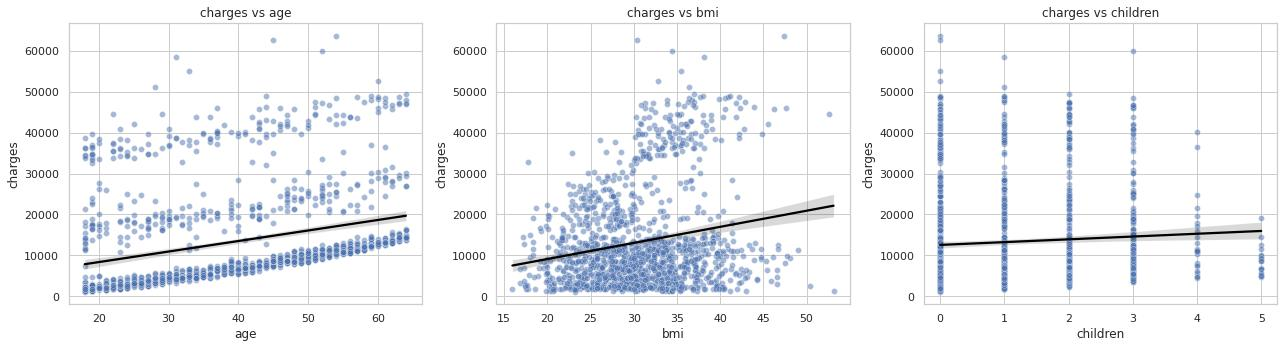

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
for eje, col in zip(ejes, ["age", "bmi", "children"]):
    sns.scatterplot(data=df, x=col, y="charges", ax=eje, alpha=0.5)
    sns.regplot(data=df, x=col, y="charges", ax=eje, scatter=False, color="black")
    eje.set_title(f"charges vs {col}")
plt.tight_layout()
plt.savefig("graficos/1_dispersion_features.png", dpi=100, bbox_inches="tight")
plt.show()

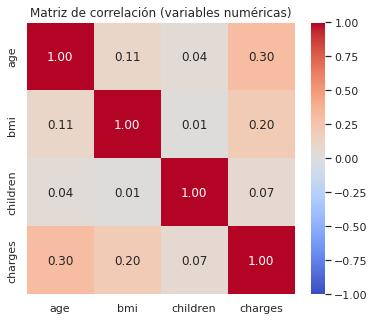

In [8]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["age", "bmi", "children", "charges"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (variables numéricas)")
plt.savefig("graficos/1_correlaciones.png", dpi=100, bbox_inches="tight")
plt.show()

Las tres features tienen correlación **positiva pero débil** con `charges`: `age` 0.30, `bmi` 0.20 y `children` 0.07. Además casi no están correlacionadas entre sí, lo que es bueno porque evita problemas de *multicolinealidad*.

En el gráfico `charges` vs `age` se ven **tres "bandas"** paralelas: para una misma edad hay grupos de costos muy distintos. Eso sugiere que existe otra variable que no estamos usando y que separa esos grupos. La exploramos con la variable categórica `smoker`:

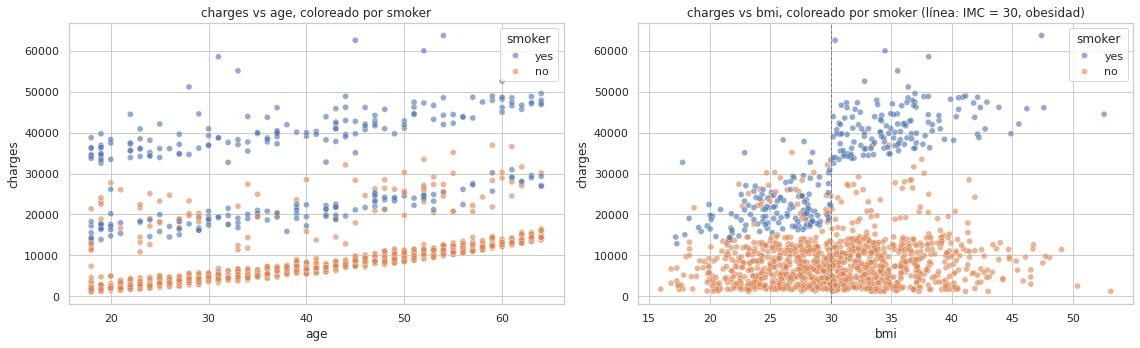

        count     mean   median
smoker                         
no       1064   8434.0   7345.0
yes       274  32050.0  34456.0


In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.6, ax=ejes[0])
ejes[0].set_title("charges vs age, coloreado por smoker")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=ejes[1])
ejes[1].axvline(30, color="gray", linestyle="--", linewidth=1)
ejes[1].set_title("charges vs bmi, coloreado por smoker (línea: IMC = 30, obesidad)")
plt.tight_layout()
plt.savefig("graficos/1_efecto_fumador.png", dpi=100, bbox_inches="tight")
plt.show()
print(df.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(0))

Las bandas se explican casi por completo por ser **fumador**: los fumadores pagan en promedio ~32.000 USD, contra ~8.400 de los no fumadores. Además, entre los fumadores el costo se dispara cuando el IMC supera 30. Lo retomamos en las conclusiones.

## 2. Cambio de estructura de datos a matricial

Para que scikit-learn entrene el modelo necesitamos:

- **X**: matriz de *n × p* (n = observaciones, p = features).
- **y**: vector de *n* valores a predecir.

Pasamos de un `DataFrame` de pandas a arrays de NumPy.

In [10]:
FEATURES = ["age", "bmi", "children"]
OBJETIVO = "charges"

X = df[FEATURES].to_numpy()   # matriz (1338, 3)
y = df[OBJETIVO].to_numpy()   # vector (1338,)

print("X:", type(X).__name__, X.shape, X.dtype)
print("y:", type(y).__name__, y.shape, y.dtype)
print("\nPrimeras 5 filas de X:\n", X[:5])
print("\nPrimeros 5 valores de y:", y[:5])

X: ndarray (1338, 3) float64
y: ndarray (1338,) float64

Primeras 5 filas de X:
 [[19.    27.9    0.   ]
 [18.    33.77   1.   ]
 [28.    33.     3.   ]
 [33.    22.705  0.   ]
 [32.    28.88   0.   ]]

Primeros 5 valores de y: [16884.924    1725.5523   4449.462   21984.47061  3866.8552 ]


## 3. Particionado de datos en Entrenamiento y Test

Usamos el **80 %** de los datos para entrenar y el **20 %** restante para evaluar con datos que el modelo nunca vio. Fijamos `random_state=42` para que la partición sea reproducible.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, y_train.shape)
print("Test:         ", X_test.shape, y_test.shape)
print(f"Promedio de charges -> train: {y_train.mean():,.0f} | test: {y_test.mean():,.0f}")

Entrenamiento: (1070, 3) (1070,)
Test:          (268, 3) (268,)
Promedio de charges -> train: 13,346 | test: 12,968


## 4. Generación del modelo con los datos de Entrenamiento

El modelo de Regresión Lineal Múltiple es:

\[ \widehat{charges} = b_0 + b_1 \cdot age + b_2 \cdot bmi + b_3 \cdot children \]

`LinearRegression` encuentra los coeficientes \(b_i\) que minimizan el error cuadrático en los datos de entrenamiento (mínimos cuadrados).

In [12]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print(f"Intercepto (b0): {modelo.intercept_:,.2f}")
coeficientes = pd.DataFrame({"feature": FEATURES, "coeficiente": modelo.coef_})
coeficientes

Intercepto (b0): -6,118.05


,feature,coeficiente
0,age,220.757765
1,bmi,332.202476
2,children,563.019432


**Interpretación de los coeficientes** (manteniendo las demás variables constantes):

- `age`: cada **año** más de edad suma ≈ **221 USD** al costo anual.
- `bmi`: cada **punto** más de IMC suma ≈ **332 USD**.
- `children`: cada **hijo** más suma ≈ **563 USD**.

⚠️ Estos coeficientes **no se pueden comparar directamente** para decidir qué variable es más influyente, porque las variables tienen escalas distintas: la edad varía en un rango de ~46 años y los hijos solo de 0 a 5. Para compararlas calculamos el **efecto estandarizado**: el coeficiente multiplicado por el desvío estándar de la variable, o sea cuánto cambia `charges` si la variable aumenta un desvío típico.

,feature,coeficiente,desvio_std_feature,efecto_estandarizado
0,age,220.76,14.05,3101.64
1,bmi,332.20,6.10,2025.83
2,children,563.02,1.21,678.72


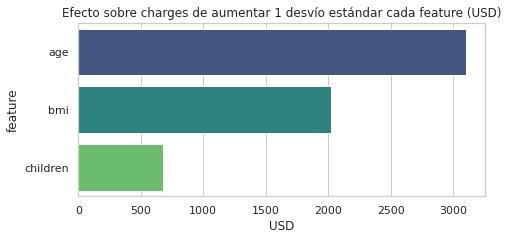

In [13]:
coeficientes["desvio_std_feature"] = df[FEATURES].std().to_numpy()
coeficientes["efecto_estandarizado"] = coeficientes["coeficiente"] * coeficientes["desvio_std_feature"]
coeficientes = coeficientes.sort_values("efecto_estandarizado", ascending=False)
display(coeficientes.round(2))

plt.figure(figsize=(7, 3.5))
sns.barplot(data=coeficientes, x="efecto_estandarizado", y="feature", hue="feature", palette="viridis", legend=False)
plt.title("Efecto sobre charges de aumentar 1 desvío estándar cada feature (USD)")
plt.xlabel("USD")
plt.tight_layout()
plt.savefig("graficos/4_influencia_features.png", dpi=100, bbox_inches="tight")
plt.show()

## 5. Evaluación del modelo con los datos de Entrenamiento

Métricas que usamos:

- **R²** (coeficiente de determinación): proporción de la variabilidad de `charges` que explica el modelo. 1 = perfecto, 0 = no mejor que predecir siempre el promedio.
- **MAE** (error absoluto medio): en promedio, cuántos USD se equivoca el modelo.
- **RMSE** (raíz del error cuadrático medio): parecido al MAE pero penaliza más los errores grandes. Está en USD.

In [14]:
def evaluar(modelo, X, y, nombre):
    pred = modelo.predict(X)
    return {
        "conjunto": nombre,
        "R2": r2_score(y, pred),
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
    }, pred

metricas_train, pred_train = evaluar(modelo, X_train, y_train, "Entrenamiento")
pd.DataFrame([metricas_train]).round(3)

,conjunto,R2,MAE,RMSE
0,Entrenamiento,0.11,9005.903,11334.682


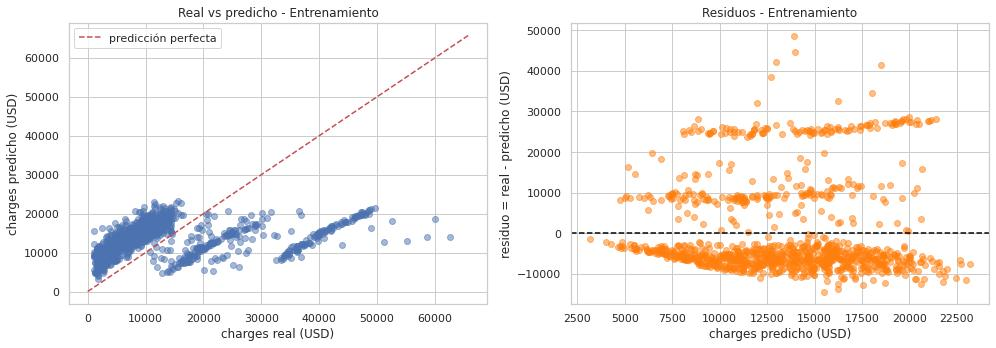

In [15]:
def graficar_predicciones(y_real, y_pred, titulo, archivo):
    fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
    ejes[0].scatter(y_real, y_pred, alpha=0.5)
    limite = [0, max(y_real.max(), y_pred.max()) * 1.05]
    ejes[0].plot(limite, limite, "r--", label="predicción perfecta")
    ejes[0].set_xlabel("charges real (USD)")
    ejes[0].set_ylabel("charges predicho (USD)")
    ejes[0].set_title(f"Real vs predicho - {titulo}")
    ejes[0].legend()
    residuos = y_real - y_pred
    ejes[1].scatter(y_pred, residuos, alpha=0.5, color="tab:orange")
    ejes[1].axhline(0, color="black", linestyle="--")
    ejes[1].set_xlabel("charges predicho (USD)")
    ejes[1].set_ylabel("residuo = real - predicho (USD)")
    ejes[1].set_title(f"Residuos - {titulo}")
    plt.tight_layout()
    plt.savefig(archivo, dpi=100, bbox_inches="tight")
    plt.show()

graficar_predicciones(y_train, pred_train, "Entrenamiento", "graficos/5_pred_entrenamiento.png")

## 6. Evaluación del modelo con los datos de Test

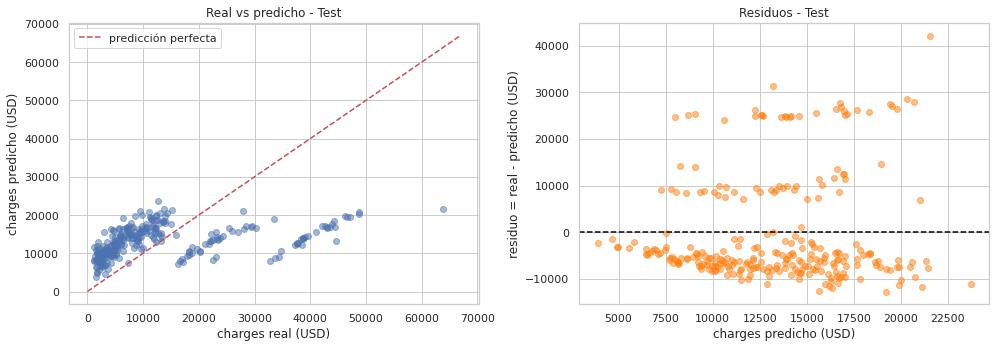

,R2,MAE,RMSE
conjunto,,,
Entrenamiento,0.110,9005.903,11334.682
Test,0.155,9181.312,11454.315


In [16]:
metricas_test, pred_test = evaluar(modelo, X_test, y_test, "Test")
graficar_predicciones(y_test, pred_test, "Test", "graficos/6_pred_test.png")

comparacion = pd.DataFrame([metricas_train, metricas_test]).set_index("conjunto")
comparacion.round(3)

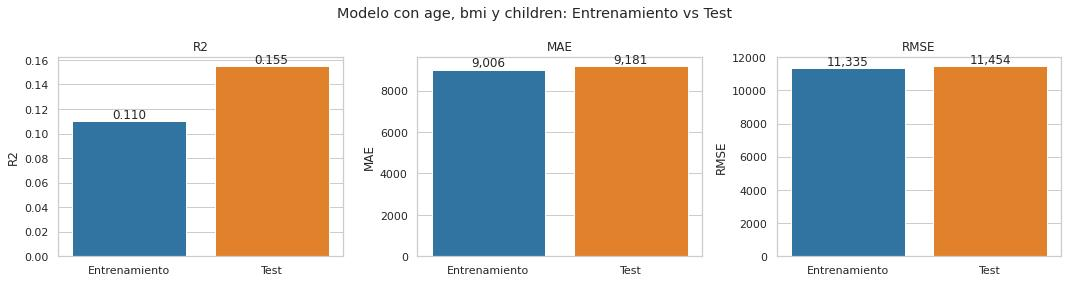

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, metrica in zip(ejes, ["R2", "MAE", "RMSE"]):
    sns.barplot(x=comparacion.index, y=comparacion[metrica], hue=comparacion.index,
                palette=["tab:blue", "tab:orange"], ax=eje, legend=False)
    eje.set_title(metrica)
    eje.set_xlabel("")
    for i, valor in enumerate(comparacion[metrica]):
        eje.text(i, valor, f"{valor:,.3f}" if metrica == "R2" else f"{valor:,.0f}", ha="center", va="bottom")
plt.suptitle("Modelo con age, bmi y children: Entrenamiento vs Test")
plt.tight_layout()
plt.savefig("graficos/6_comparacion_train_test.png", dpi=100, bbox_inches="tight")
plt.show()

**Resultado del modelo pedido (age, bmi, children):** el R² es bajo, de ≈ 0.11 en entrenamiento y ≈ 0.16 en test. El modelo explica solo entre el 11 % y el 16 % de la variabilidad de los costos y se equivoca en promedio unos 9.000 USD (MAE), cuando el costo promedio es de unos 13.000 USD.

En los gráficos de "real vs predicho" se ve que el modelo nunca predice más de ~20.000 USD y subestima sistemáticamente a las personas con costos altos (los puntos de arriba a la derecha en los residuos). Esas personas son, como vimos en el paso 1, los **fumadores**.

## Extra: ¿mejora el modelo con otras features?

Para responder si las features elegidas son buenas predictoras, repetimos los pasos 2 a 6 con **todas las variables del dataset**. Las categóricas se transforman a números con *one-hot encoding* (`pd.get_dummies`):

- `smoker_yes` = 1 si fuma, 0 si no,
- `sex_male` = 1 si es hombre,
- `region_*` = una columna por región, tomando `northeast` como referencia.

Además probamos una *feature* nueva sugerida por el gráfico del paso 1: **`fumador_obeso` = fumador y con IMC ≥ 30**.

Usamos la misma partición (`random_state=42`) para que la comparación sea justa.

In [18]:
df_cod = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
df_cod["fumador_obeso"] = ((df["smoker"] == "yes") & (df["bmi"] >= 30)).astype(int)
df_cod.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,fumador_obeso
0,19,27.900,0,16884.92400,0,1,0,0,1,0
1,18,33.770,1,1725.55230,1,0,0,1,0,0
2,28,33.000,3,4449.46200,1,0,0,1,0,0
3,33,22.705,0,21984.47061,1,0,1,0,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0,0


In [19]:
conjuntos_features = {
    "1) age, bmi, children (modelo pedido)": FEATURES,
    "2) + smoker": FEATURES + ["smoker_yes"],
    "3) todas las variables": [c for c in df_cod.columns if c not in ("charges", "fumador_obeso")],
    "4) todas + fumador_obeso": [c for c in df_cod.columns if c != "charges"],
}

filas, modelos = [], {}
for nombre, cols in conjuntos_features.items():
    Xc = df_cod[cols].to_numpy()
    Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, df_cod["charges"].to_numpy(), test_size=0.2, random_state=42)
    m = LinearRegression().fit(Xc_tr, yc_tr)
    modelos[nombre] = (m, cols, Xc_te, yc_te)
    for conj, Xe, ye in [("Entrenamiento", Xc_tr, yc_tr), ("Test", Xc_te, yc_te)]:
        met, _ = evaluar(m, Xe, ye, conj)
        filas.append({"modelo": nombre, **met})

resultados = pd.DataFrame(filas).pivot(index="modelo", columns="conjunto", values=["R2", "MAE", "RMSE"])
resultados.round(3)

R2                  MAE  \
conjunto                              Entrenamiento   Test Entrenamiento   
modelo                                                                     
1) age, bmi, children (modelo pedido)         0.110  0.155      9005.903   
2) + smoker                                   0.741  0.781      4210.664   
3) todas las variables                        0.742  0.784      4208.235   
4) todas + fumador_obeso                      0.861  0.872      2511.244   

                                                         RMSE             
conjunto                                   Test Entrenamiento       Test  
modelo                                                                    
1) age, bmi, children (modelo pedido)  9181.312     11334.682  11454.315  
2) + smoker                            4213.799      6113.068   5829.379  
3) todas las variables                 4181.194      6105.545   5796.285  
4) todas + fumador_obeso               2486.315      4480.063   4458.275

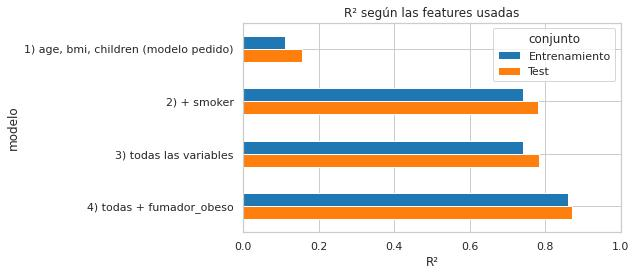

In [20]:
r2 = resultados["R2"]
r2.plot(kind="barh", figsize=(9, 4), color=["tab:blue", "tab:orange"])
plt.xlabel("R²")
plt.title("R² según las features usadas")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("graficos/extra_comparacion_modelos.png", dpi=100, bbox_inches="tight")
plt.show()

,feature,coeficiente,efecto_estandarizado
8,fumador_obeso,19850.7,6172.9
4,smoker_yes,13292.2,5366.0
0,age,261.8,3678.4
7,region_southwest,-1371.8,-588.5
2,children,469.8,566.3
1,bmi,56.6,345.0
6,region_southeast,-692.2,-308.1
3,sex_male,-502.4,-251.3
5,region_northwest,-339.0,-145.4


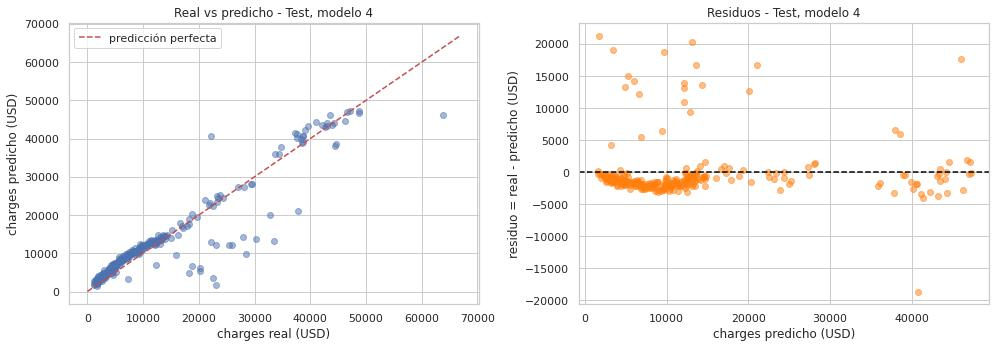

In [21]:
m4, cols4, X4_te, y4_te = modelos["4) todas + fumador_obeso"]
coef4 = pd.DataFrame({"feature": cols4, "coeficiente": m4.coef_})
coef4["efecto_estandarizado"] = coef4["coeficiente"] * df_cod[cols4].std().to_numpy()
display(coef4.sort_values("efecto_estandarizado", key=abs, ascending=False).round(1))

graficar_predicciones(y4_te, m4.predict(X4_te), "Test, modelo 4", "graficos/extra_pred_test_modelo4.png")

## Conclusiones

**1. ¿Cuál fue el desempeño del modelo?**
El modelo pedido, con las features numéricas `age`, `bmi` y `children`, tiene un desempeño **pobre**: R² ≈ 0.11 en entrenamiento y ≈ 0.16 en test, con un error medio (MAE) de ~9.000 USD y un RMSE de ~11.400 USD. Explica solo una pequeña parte de la variabilidad de los costos médicos y subestima mucho a las personas con costos altos.

**2. ¿Qué variable fue la más influyente según los coeficientes?**
Si miramos el coeficiente "crudo", `children` tiene el más grande (≈ 563 USD por hijo), pero eso es engañoso porque las variables tienen escalas distintas. Comparando el **efecto estandarizado** (coeficiente × desvío estándar), la más influyente es **`age`** (≈ 3.100 USD por cada desvío de ~14 años), seguida por `bmi` (≈ 2.000 USD) y, muy atrás, `children` (≈ 700 USD). Esto coincide con las correlaciones del paso 1 (0.30, 0.20 y 0.07).

**3. ¿Las features extraídas fueron buenas predictoras? ¿Sugerimos otras?**
Por sí solas **no fueron buenas predictoras**: están relacionadas con el costo, pero la relación es débil. La exploración mostró que la variable clave es **`smoker`**. Agregándola, el R² en test sube de 0.16 a ≈ 0.78 y el MAE baja de ~9.200 a ~4.200 USD. En cambio, sumar `sex` y `region` casi no cambia nada (R² 0.784): aportan muy poco. Además, la interacción **fumador con obesidad (IMC ≥ 30)** sube el R² en test a ≈ 0.87 y baja el MAE a ~2.500 USD. Esto pasa porque un modelo lineal por sí solo no puede capturar que el efecto del IMC dependa de si la persona fuma. En ese último modelo, `fumador_obeso` y `smoker_yes` son las variables más influyentes (efecto estandarizado de ~6.200 y ~5.400 USD), seguidas por `age` (~3.700 USD). El coeficiente propio de `bmi` se vuelve chico porque casi todo su efecto lo absorbe la interacción. **Sugerimos usar `smoker` y esa interacción.** Otras variables que podrían mejorar el modelo, pero no están en el dataset, son enfermedades preexistentes, actividad física o tipo de plan contratado.

**4. Comparativa de resultados con Entrenamiento y Test**
Los resultados en entrenamiento y en test son **muy parecidos** en todos los modelos (por ejemplo, para el modelo pedido el R² es 0.11 vs 0.16 y el RMSE 11.335 vs 11.454 USD). Entonces **no hay sobreajuste (overfitting)**: el modelo generaliza a datos nuevos igual de bien (o de mal) que a los de entrenamiento. Que el test dé incluso un poco mejor se debe al azar de la partición: el 20 % de test tiene pocas observaciones (268) y algunas personas con costos extremos quedaron en entrenamiento. El problema del modelo pedido es de **subajuste (underfitting)**: le faltan variables explicativas, no le sobra complejidad.